<!-- @format -->

# Comparative Evaluation


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

while not (
    (PROJECT_ROOT / "data_loader.py").is_file() and (PROJECT_ROOT / "models").is_dir()
):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not locate the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")

Project root: D:\Main\sem5\deep-learning\ASG_2


<!-- @format -->

## Setup and imports


In [2]:
import json
import re
import time

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from data_loader import get_dataloaders
from models.autoencoder import build_vanilla_autoencoder
from models.dcgan import build_dcgan_generator
from models.ddpm import build_noise_predictor, predict_noise
from models.sparse_autoencoder import build_sparse_autoencoder
from models.vae import build_vae
from models.vanilla_gan import build_generator
from utils.metrics import psnr, ssim
from utils.paths import (
    CHECKPOINT_DIR,
    DATA_DIR,
    FIGURES_DIR,
    METRICS_DIR,
    ensure_results_dirs,
    get_device,
)
from utils.reproducibility import set_seed

SEED = 42
BATCH_SIZE = 128
NUM_SAMPLES = 16
BATCH_LATENCY = 64
LATENT_DIM_AE = 64
LATENT_DIM_GAN = 100
TIMESTEPS = 500
BETA_START = 1e-4
BETA_END = 0.02

DEVICE = get_device()
set_seed(SEED)
ensure_results_dirs()

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

print(f"Device: {DEVICE}")

Device: cpu


<!-- @format -->

## Load the Fashion-MNIST test split

The same `data_loader.get_dataloaders()` split used by every training notebook is
used here, so all comparisons are made on the same 7,000 test images.


In [3]:
train_loader, val_loader, test_loader = get_dataloaders(
    root=DATA_DIR,
    batch_size=BATCH_SIZE,
    seed=SEED,
)

test_images = torch.cat([images for images, _ in test_loader])
test_labels = torch.cat([labels for _, labels in test_loader])

print(f"Training samples:   {len(train_loader.dataset)}")
print(f"Validation samples: {len(val_loader.dataset)}")
print(f"Test samples:       {len(test_loader.dataset)}")
print(f"Test image tensor:  {tuple(test_images.shape)}")

Training samples:   56000
Validation samples: 7000
Test samples:       7000
Test image tensor:  (7000, 1, 28, 28)


<!-- @format -->

## Load metrics and trained checkpoints

Every checkpoint is loaded with `weights_only=True`. The available metadata is
not identical across models, so each model is handled according to what its
checkpoint and metrics file actually contain.


In [ ]:
def read_metrics(filename):
    path = METRICS_DIR / filename
    if not path.is_file():
        print(f"Missing metrics file: {path.name}")
        return None
    return json.loads(path.read_text(encoding="utf-8"))


metrics = {
    "vanilla_ae": read_metrics("vanilla_ae.json"),
    "sparse_ae": read_metrics("sparse_ae.json"),
    "vae": read_metrics("vae.json"),
    "vanilla_gan": read_metrics("vanilla_gan.json"),
    "dcgan": read_metrics("dcgan.json"),
    "ddpm": read_metrics("ddpm.json"),
    "mlp_classifier": read_metrics("mlp_classifier.json"),
    "mlp_classifier_analysis": read_metrics("mlp_classifier_analysis.json"),
}

checkpoint_files = {
    "vanilla_ae": "vanilla_ae_best.pth",
    "sparse_ae": "sparse_ae_best.pth",
    "vae": "vae_best.pth",
    "vanilla_gan": "vanilla_gan_best.pth",
    "dcgan": "dcgan_final.pth",
    "ddpm": "ddpm_best.pth",
}

checkpoints = {}

for name, filename in checkpoint_files.items():
    path = CHECKPOINT_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f"Checkpoint not found: {path}")
    checkpoints[name] = torch.load(path, map_location=DEVICE, weights_only=True)
    print(f"Loaded {name:<12} from {filename}")

if metrics["dcgan"] is None:
    print(
        "DCGAN metrics JSON is unavailable; configuration is recovered from its checkpoint."
    )

Missing metrics file: dcgan.json
Loaded vanilla_ae   from vanilla_ae_best.pth
Loaded sparse_ae    from sparse_ae_best.pth
Loaded vae          from vae_best.pth
Loaded vanilla_gan  from vanilla_gan_best.pth
Loaded dcgan        from dcgan_final.pth
Loaded ddpm         from ddpm_best.pth
DCGAN metrics JSON is unavailable; configuration is recovered from its checkpoint.


<!-- @format -->

## Initialise architectures and load trained weights


In [ ]:
LATENT_DIM_AE = int(checkpoints["vae"].get("latent_dim", LATENT_DIM_AE))
LATENT_DIM_GAN = int(checkpoints["dcgan"].get("latent_dim", LATENT_DIM_GAN))

vanilla_ae = build_vanilla_autoencoder(LATENT_DIM_AE).to(DEVICE)
vanilla_ae.load_state_dict(checkpoints["vanilla_ae"])
vanilla_ae.eval()
vanilla_ae_decoder = vanilla_ae[5:]

sparse_encoder, sparse_decoder = build_sparse_autoencoder(LATENT_DIM_AE)
sparse_encoder = sparse_encoder.to(DEVICE)
sparse_decoder = sparse_decoder.to(DEVICE)
sparse_encoder.load_state_dict(checkpoints["sparse_ae"]["encoder_state_dict"])
sparse_decoder.load_state_dict(checkpoints["sparse_ae"]["decoder_state_dict"])
sparse_encoder.eval()
sparse_decoder.eval()

vae_encoder, vae_fc_mu, vae_fc_log_var, vae_decoder = build_vae(LATENT_DIM_AE)
vae_encoder = vae_encoder.to(DEVICE)
vae_fc_mu = vae_fc_mu.to(DEVICE)
vae_fc_log_var = vae_fc_log_var.to(DEVICE)
vae_decoder = vae_decoder.to(DEVICE)
vae_encoder.load_state_dict(checkpoints["vae"]["encoder_state_dict"])
vae_fc_mu.load_state_dict(checkpoints["vae"]["fc_mu_state_dict"])
vae_fc_log_var.load_state_dict(checkpoints["vae"]["fc_log_var_state_dict"])
vae_decoder.load_state_dict(checkpoints["vae"]["decoder_state_dict"])
vae_encoder.eval()
vae_fc_mu.eval()
vae_fc_log_var.eval()
vae_decoder.eval()

vanilla_gan_generator = build_generator(LATENT_DIM_GAN).to(DEVICE)
vanilla_gan_generator.load_state_dict(
    checkpoints["vanilla_gan"]["generator_state_dict"]
)
vanilla_gan_generator.eval()

dcgan_generator = build_dcgan_generator(LATENT_DIM_GAN).to(DEVICE)
dcgan_generator.load_state_dict(checkpoints["dcgan"]["generator_state_dict"])
dcgan_generator.eval()

ddpm_noise_predictor = build_noise_predictor().to(DEVICE)
ddpm_noise_predictor.load_state_dict(checkpoints["ddpm"]["model_state_dict"])
ddpm_noise_predictor.eval()

print(f"AE-family latent dimension: {LATENT_DIM_AE}")
print(f"GAN latent dimension:       {LATENT_DIM_GAN}")
print(f"DDPM timesteps:             {checkpoints['ddpm'].get('timesteps', TIMESTEPS)}")

AE-family latent dimension: 64
GAN latent dimension:       100
DDPM timesteps:             500


<!-- @format -->

## DDPM noise schedule and reverse process


In [6]:
TIMESTEPS = int(checkpoints["ddpm"].get("timesteps", TIMESTEPS))

betas = torch.linspace(BETA_START, BETA_END, TIMESTEPS, device=DEVICE)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)

print(f"Diffusion timesteps: {TIMESTEPS}")
print(f"Alpha bar at t=0:    {alpha_bars[0].item():.6f}")
print(f"Alpha bar at t=end:  {alpha_bars[-1].item():.6f}")


@torch.inference_mode()
def reverse_diffusion(model, num_samples=NUM_SAMPLES, capture_steps=None):
    """Sample with the same reverse process used in the DDPM notebook.

    When ``capture_steps`` is given, the initial Gaussian noise and the selected
    denoising steps are returned in chronological (high-t to low-t) order.
    """
    model.eval()

    images = torch.randn(num_samples, 1, 28, 28, device=DEVICE)
    trajectory = []

    if capture_steps is not None:
        trajectory.append((TIMESTEPS, images.detach().cpu().clone()))

    for t in reversed(range(TIMESTEPS)):
        timesteps = torch.full(
            (num_samples,),
            t,
            device=DEVICE,
            dtype=torch.long,
        )

        predicted_noise = predict_noise(images, timesteps, model, TIMESTEPS)

        alpha_t = alphas[t]
        alpha_bar_t = alpha_bars[t]
        beta_t = betas[t]

        images = (1.0 / torch.sqrt(alpha_t)) * (
            images - (beta_t / torch.sqrt(1.0 - alpha_bar_t)) * predicted_noise
        )

        if t > 0:
            images = images + torch.sqrt(beta_t) * torch.randn_like(images)

        if capture_steps is not None and t in capture_steps:
            trajectory.append((t, images.detach().cpu().clone()))

    return images.clamp(-1.0, 1.0), trajectory

Diffusion timesteps: 500
Alpha bar at t=0:    0.999900
Alpha bar at t=end:  0.006353


<!-- @format -->

## Forward-pass validation

A quick shape check for every loaded model before generating any figures.


In [ ]:
with torch.inference_mode():
    sample = test_images[:4].to(DEVICE)

    ae_output = vanilla_ae(sample.flatten(start_dim=1)).reshape(-1, 1, 28, 28)
    sparse_output = sparse_decoder(sparse_encoder(sample))
    vae_output = vae_decoder(vae_fc_mu(vae_encoder(sample)))

    vanilla_gan_output = vanilla_gan_generator(
        torch.randn(4, LATENT_DIM_GAN, device=DEVICE)
    )
    dcgan_output = dcgan_generator(torch.randn(4, LATENT_DIM_GAN, 1, 1, device=DEVICE))

    ddpm_timesteps = torch.full((4,), TIMESTEPS - 1, device=DEVICE, dtype=torch.long)
    ddpm_output = predict_noise(
        torch.randn(4, 1, 28, 28, device=DEVICE),
        ddpm_timesteps,
        ddpm_noise_predictor,
        TIMESTEPS,
    )

for name, output in {
    "Vanilla AE": ae_output,
    "Sparse AE": sparse_output,
    "VAE": vae_output,
    "Vanilla GAN": vanilla_gan_output,
    "DCGAN": dcgan_output,
    "DDPM noise prediction": ddpm_output,
}.items():
    assert output.shape == (4, 1, 28, 28), (name, output.shape)
    print(f"{name:<24} {tuple(output.shape)}")

Vanilla AE               (4, 1, 28, 28)
Sparse AE                (4, 1, 28, 28)
VAE                      (4, 1, 28, 28)
Vanilla GAN              (4, 1, 28, 28)
DCGAN                    (4, 1, 28, 28)
DDPM noise prediction    (4, 1, 28, 28)


<!-- @format -->

## 1. Reconstruction comparison: AE, Sparse AE, VAE


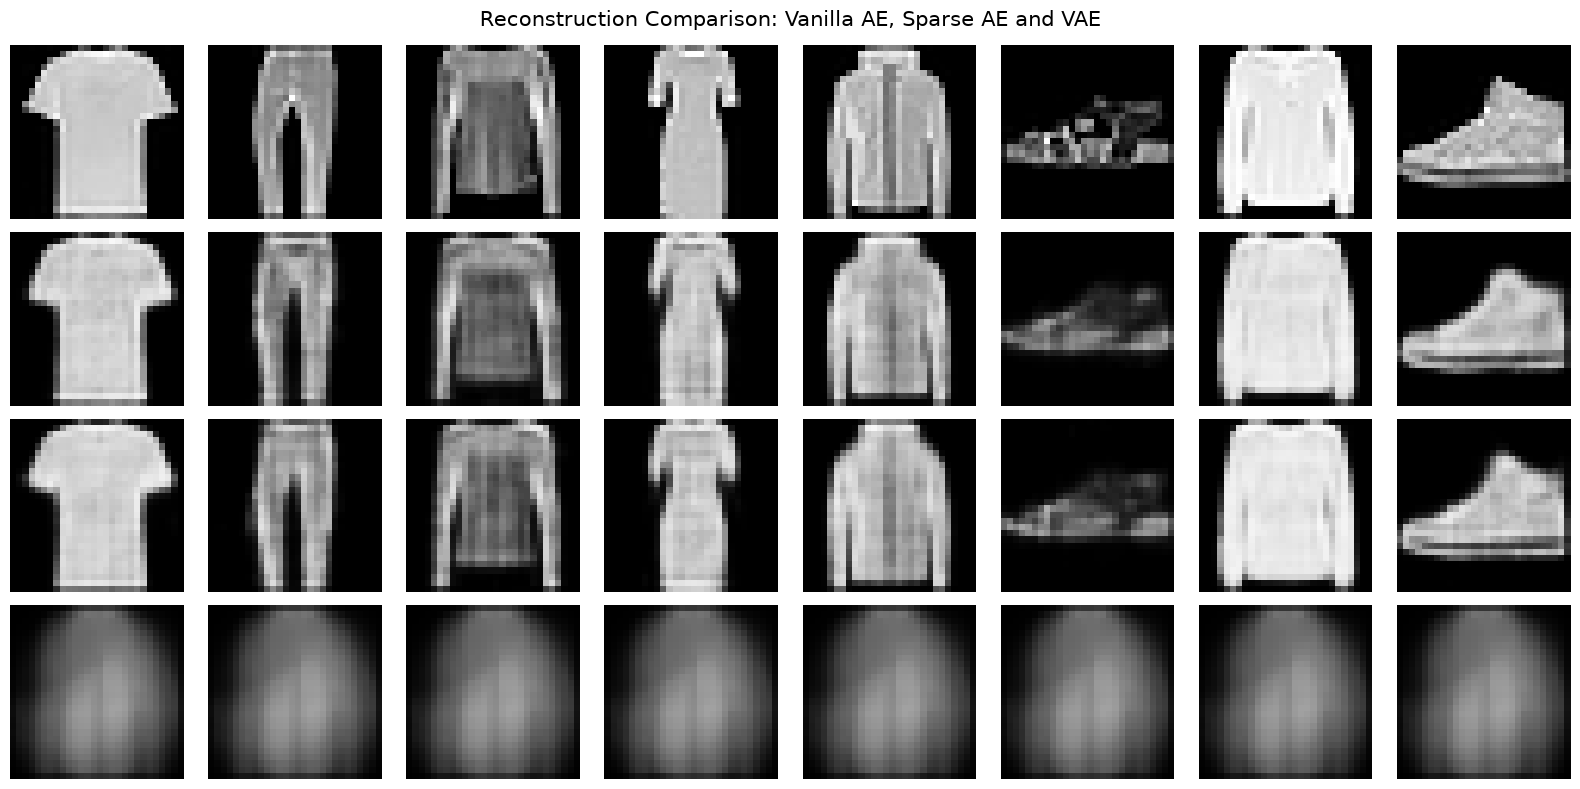

Saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\reconstruction_comparison.png


In [8]:
def reconstruct_vanilla(images):
    return vanilla_ae(images.flatten(start_dim=1)).reshape(-1, 1, 28, 28)


def reconstruct_sparse(images):
    return sparse_decoder(sparse_encoder(images))


def reconstruct_vae(images):
    # Deterministic reconstruction: decode the posterior mean.
    return vae_decoder(vae_fc_mu(vae_encoder(images)))


selection = []
for label in range(10):
    index = (test_labels == label).nonzero(as_tuple=True)[0][0].item()
    selection.append(index)
    if len(selection) == 8:
        break

selection = torch.tensor(selection)
original = test_images[selection].to(DEVICE)

with torch.inference_mode():
    reconstructed = {
        "Vanilla AE": reconstruct_vanilla(original),
        "Sparse AE": reconstruct_sparse(original),
        "VAE": reconstruct_vae(original),
    }

reconstruction_samples = {"Original": original.cpu()}
reconstruction_samples.update(
    {name: tensor.cpu() for name, tensor in reconstructed.items()}
)

row_titles = ["Original", "Vanilla AE", "Sparse AE", "VAE"]
fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for row, title in enumerate(row_titles):
    image_row = reconstruction_samples[title]
    for column in range(8):
        axes[row, column].imshow(
            image_row[column, 0].numpy(),
            cmap="gray",
            vmin=0,
            vmax=1,
        )
        axes[row, column].axis("off")
    axes[row, 0].set_ylabel(title, rotation=90, fontsize=10, labelpad=12)

fig.suptitle("Reconstruction Comparison: Vanilla AE, Sparse AE and VAE", fontsize=15)
plt.tight_layout()

reconstruction_path = FIGURES_DIR / "reconstruction_comparison.png"
fig.savefig(reconstruction_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Saved: {reconstruction_path}")

<!-- @format -->

## Consistent AE-family reconstruction metrics

The existing `sparse_ae.json` used a `reduction="sum"` value divided by the number
of images, while the other models used a per-pixel mean. To avoid comparing
different reduction conventions, all three reconstruction models are re-scored
here on the same test set with:

- MSE: mean squared error over every pixel,
- PSNR: `utils.metrics.psnr`,
- SSIM: `utils.metrics.ssim`.

The VAE uses its posterior mean for a deterministic reconstruction.


In [9]:
def reconstruction_metrics(reconstruct_fn):
    squared_error = 0.0
    value_count = 0
    psnr_total = 0.0
    ssim_total = 0.0
    sample_count = 0

    with torch.inference_mode():
        for images, _ in test_loader:
            images = images.to(DEVICE)
            recons = reconstruct_fn(images)

            squared_error += ((recons - images) ** 2).sum().item()
            value_count += images.numel()

            psnr_total += psnr(recons, images).item() * images.size(0)
            ssim_total += ssim(recons, images).item() * images.size(0)
            sample_count += images.size(0)

    return {
        "mse": squared_error / value_count,
        "psnr": psnr_total / sample_count,
        "ssim": ssim_total / sample_count,
    }


recomputed_metrics = {
    "Vanilla AE": reconstruction_metrics(reconstruct_vanilla),
    "Sparse AE": reconstruction_metrics(reconstruct_sparse),
    "VAE": reconstruction_metrics(reconstruct_vae),
}

for name, values in recomputed_metrics.items():
    print(
        f"{name:<12} MSE={values['mse']:.6f}  "
        f"PSNR={values['psnr']:.2f} dB  SSIM={values['ssim']:.4f}"
    )

Vanilla AE   MSE=0.008022  PSNR=20.97 dB  SSIM=0.7476
Sparse AE    MSE=0.007944  PSNR=21.01 dB  SSIM=0.7519
VAE          MSE=0.087502  PSNR=10.58 dB  SSIM=0.1288


<!-- @format -->

## 2. Random generation comparison

Each model produces a 4x4 grid from its own latent or noise prior.


In [10]:
with torch.inference_mode():
    vae_samples = vae_decoder(
        torch.randn(NUM_SAMPLES, LATENT_DIM_AE, device=DEVICE)
    ).cpu()

    vanilla_gan_samples = vanilla_gan_generator(
        torch.randn(NUM_SAMPLES, LATENT_DIM_GAN, device=DEVICE)
    )
    vanilla_gan_samples = ((vanilla_gan_samples + 1.0) / 2.0).clamp(0, 1).cpu()

    dcgan_samples = dcgan_generator(
        torch.randn(NUM_SAMPLES, LATENT_DIM_GAN, 1, 1, device=DEVICE)
    )
    dcgan_samples = ((dcgan_samples + 1.0) / 2.0).clamp(0, 1).cpu()

ddpm_samples, ddpm_trajectory = reverse_diffusion(
    ddpm_noise_predictor,
    num_samples=NUM_SAMPLES,
    capture_steps={400, 300, 200, 100, 50, 10, 0},
)
ddpm_samples = ((ddpm_samples + 1.0) / 2.0).clamp(0, 1).cpu()

print(f"VAE samples:         {tuple(vae_samples.shape)}")
print(f"Vanilla GAN samples: {tuple(vanilla_gan_samples.shape)}")
print(f"DCGAN samples:       {tuple(dcgan_samples.shape)}")
print(f"DDPM samples:        {tuple(ddpm_samples.shape)}")

VAE samples:         (16, 1, 28, 28)
Vanilla GAN samples: (16, 1, 28, 28)
DCGAN samples:       (16, 1, 28, 28)
DDPM samples:        (16, 1, 28, 28)


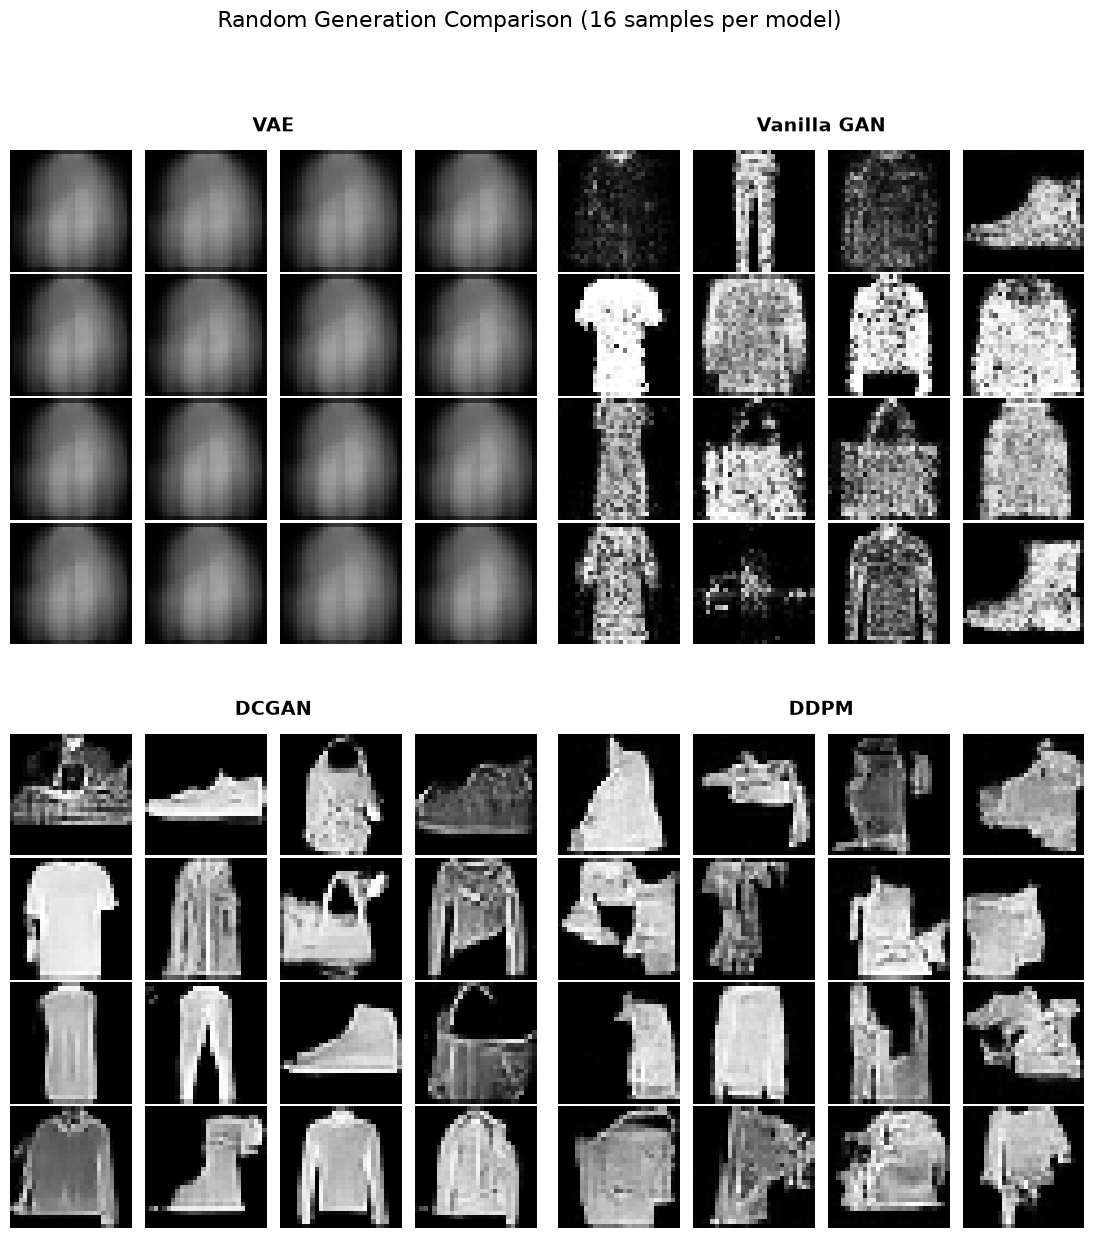

Saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\random_generation_comparison.png


In [11]:
sample_grids = {
    "VAE": vae_samples,
    "Vanilla GAN": vanilla_gan_samples,
    "DCGAN": dcgan_samples,
    "DDPM": ddpm_samples,
}

fig = plt.figure(figsize=(14, 14))
outer = fig.add_gridspec(2, 2, hspace=0.18, wspace=0.02)

for panel, (name, grid) in enumerate(sample_grids.items()):
    row, column = divmod(panel, 2)
    inner = outer[row, column].subgridspec(4, 4, hspace=0.02, wspace=0.02)

    for index in range(16):
        ax = fig.add_subplot(inner[index // 4, index % 4])
        ax.imshow(grid[index, 0].numpy(), cmap="gray", vmin=0, vmax=1)
        ax.axis("off")

    position = outer[row, column].get_position(fig)
    fig.text(
        (position.x0 + position.x1) / 2,
        position.y1 + 0.01,
        name,
        ha="center",
        va="bottom",
        fontsize=14,
        fontweight="bold",
    )

fig.suptitle("Random Generation Comparison (16 samples per model)", fontsize=16)
generation_path = FIGURES_DIR / "random_generation_comparison.png"
fig.savefig(generation_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Saved: {generation_path}")

<!-- @format -->

## 3. MLP classifier limitations

The MLP experiments were produced by `08_classifier_analysis.ipynb`. This cell
compiles the existing experiment figures into one comparative panel.


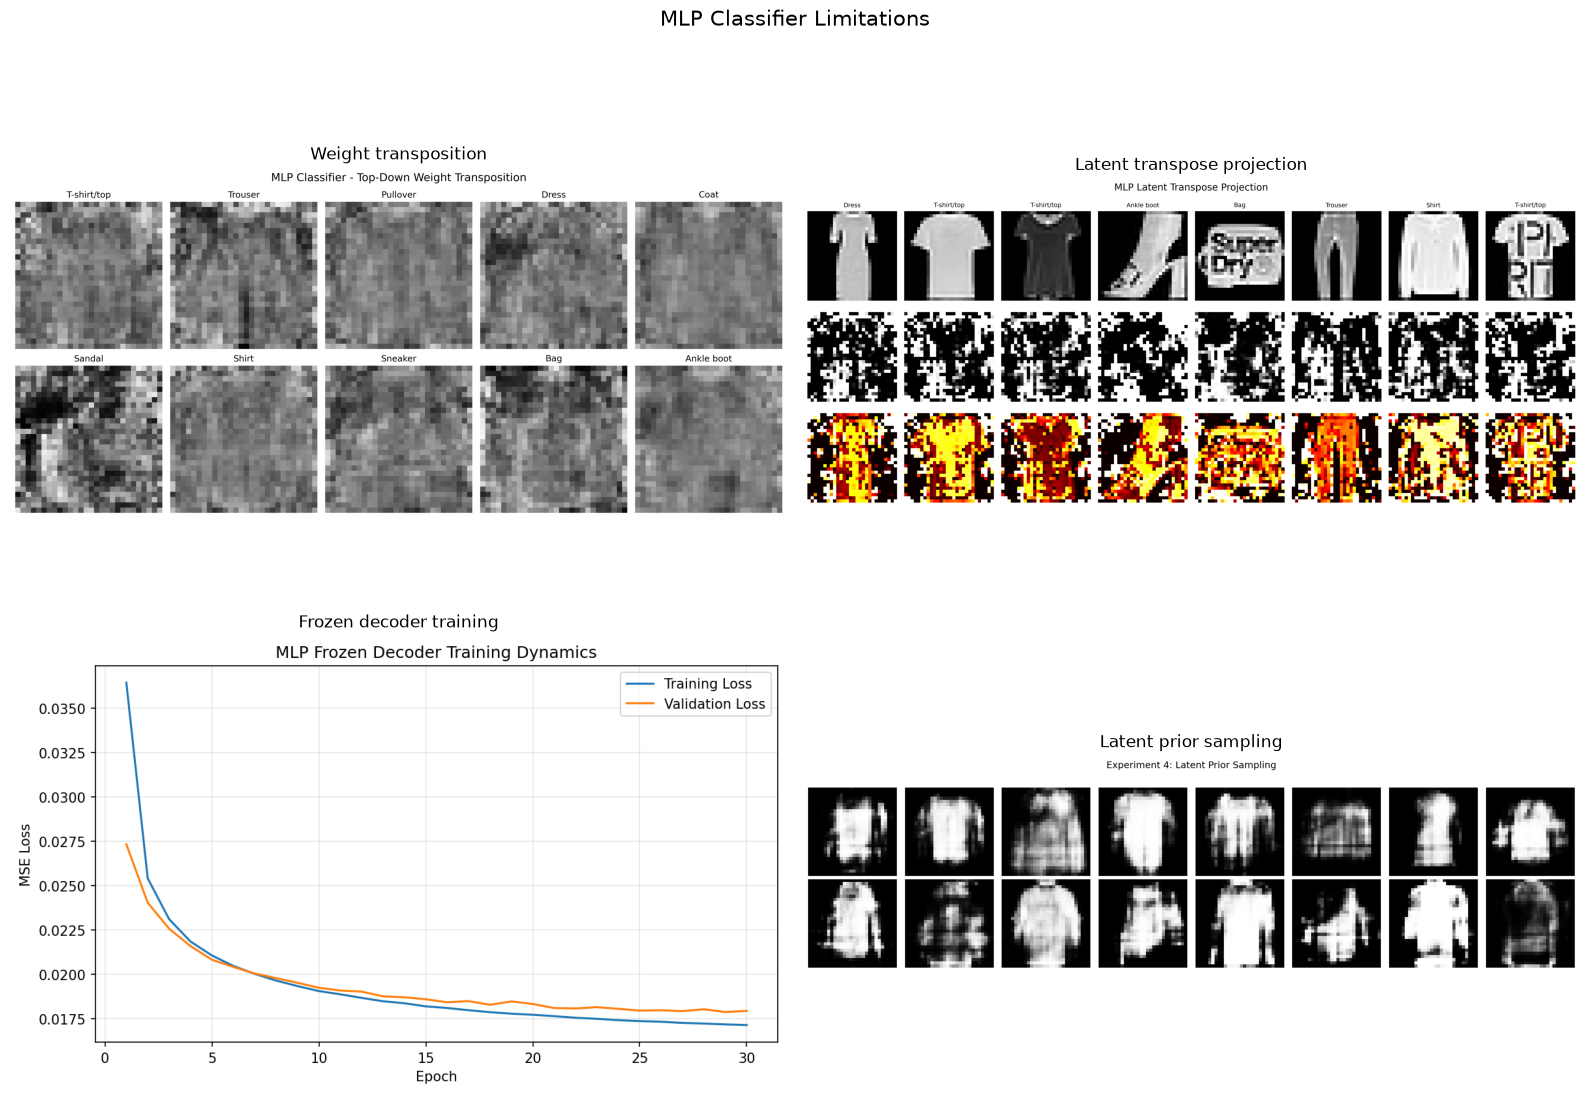

Saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\mlp_limitations_comparison.png


In [ ]:
mlp_parts = [
    ("Weight transposition", FIGURES_DIR / "exp1_weight_transposition.png"),
    (
        "Latent transpose projection",
        FIGURES_DIR / "exp2_latent_transpose_projection.png",
    ),
    ("Frozen decoder training", FIGURES_DIR / "mlp_frozen_decoder_training_curves.png"),
    ("Latent prior sampling", FIGURES_DIR / "mlp_latent_prior_sampling.png"),
]

missing_parts = [str(path) for _, path in mlp_parts if not path.is_file()]

if missing_parts:
    print("MLP component figures are missing:")
    for path in missing_parts:
        print(f"  {path}")
else:
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    for ax, (title, path) in zip(axes.flat, mlp_parts):
        ax.imshow(plt.imread(path))
        ax.set_title(title, fontsize=12)
        ax.axis("off")

    fig.suptitle("MLP Classifier Limitations", fontsize=15)
    plt.tight_layout()

    mlp_path = FIGURES_DIR / "mlp_limitations_comparison.png"
    fig.savefig(mlp_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved: {mlp_path}")

<!-- @format -->

## 4. Latent interpolation comparison


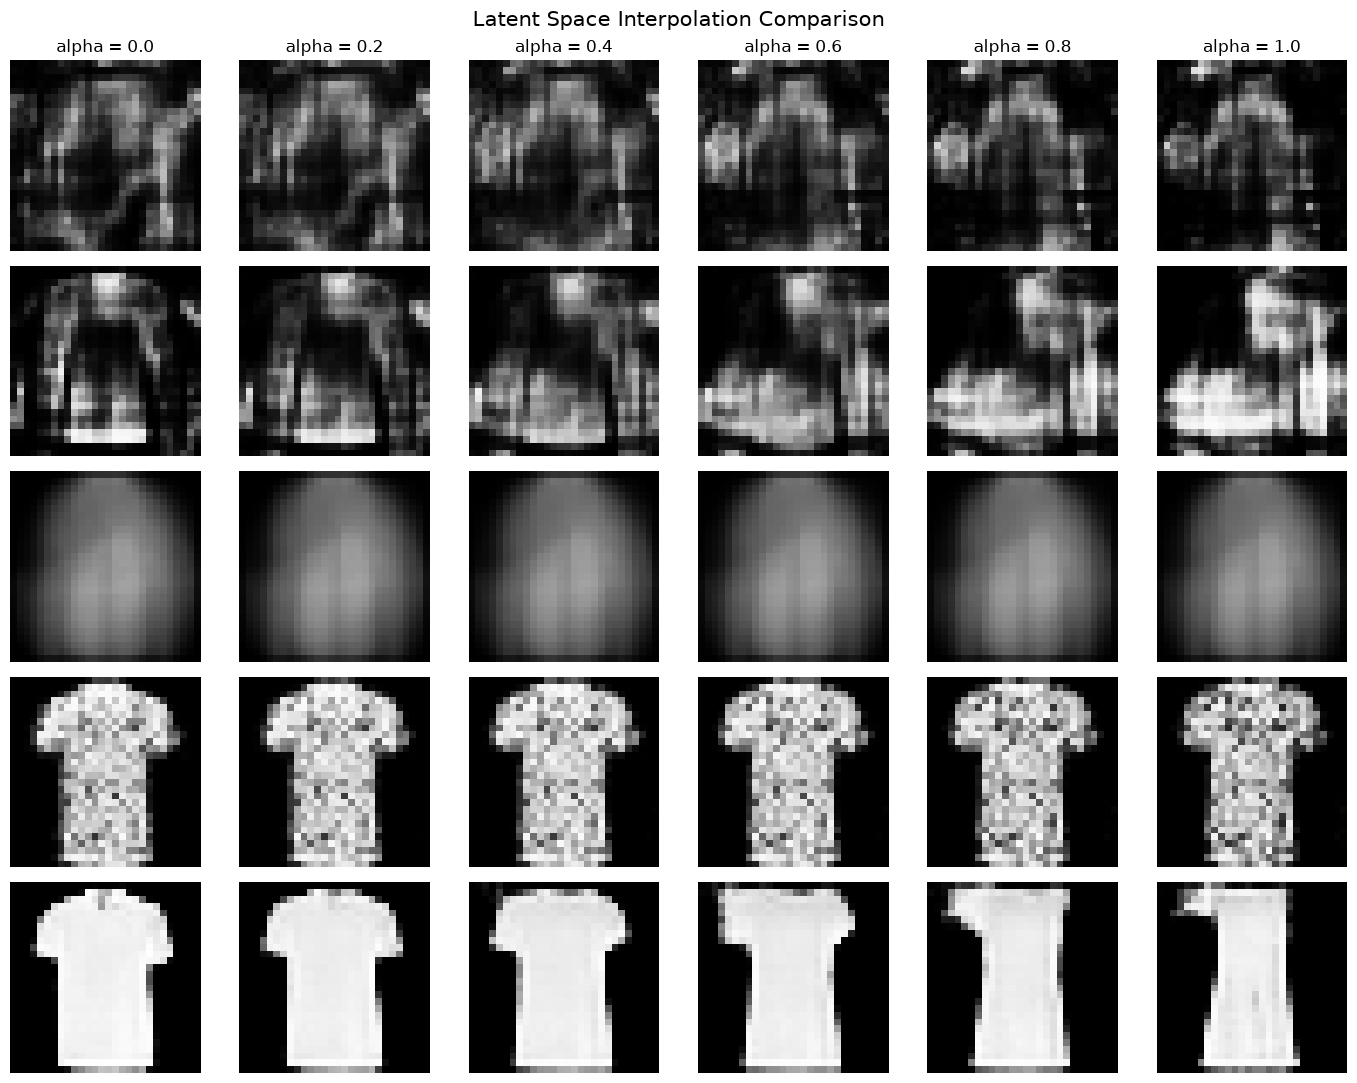

Saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\latent_interpolation_comparison.png


In [13]:
interpolation_alphas = torch.linspace(0.0, 1.0, 6, device=DEVICE)


def interpolate_ae(decoder_fn):
    z_a = torch.randn(1, LATENT_DIM_AE, device=DEVICE)
    z_b = torch.randn(1, LATENT_DIM_AE, device=DEVICE)
    with torch.inference_mode():
        images = torch.cat(
            [
                decoder_fn((1.0 - alpha) * z_a + alpha * z_b)
                for alpha in interpolation_alphas
            ]
        )
    if images.ndim == 2:
        images = images.reshape(-1, 1, 28, 28)
    return images.cpu()


def interpolate_gan(generator_fn, convolutional=False):
    shape = (1, LATENT_DIM_GAN, 1, 1) if convolutional else (1, LATENT_DIM_GAN)
    z_a = torch.randn(shape, device=DEVICE)
    z_b = torch.randn(shape, device=DEVICE)
    with torch.inference_mode():
        images = torch.cat(
            [
                generator_fn((1.0 - alpha) * z_a + alpha * z_b)
                for alpha in interpolation_alphas
            ]
        )
    return ((images + 1.0) / 2.0).clamp(0, 1).cpu()


interpolation_rows = {
    "Vanilla AE": interpolate_ae(vanilla_ae_decoder),
    "Sparse AE": interpolate_ae(sparse_decoder),
    "VAE": interpolate_ae(vae_decoder),
    "Vanilla GAN": interpolate_gan(vanilla_gan_generator),
    "DCGAN": interpolate_gan(dcgan_generator, convolutional=True),
}

fig, axes = plt.subplots(5, 6, figsize=(14, 11))

for row, (name, images) in enumerate(interpolation_rows.items()):
    for column in range(6):
        axes[row, column].imshow(
            images[column, 0].numpy(),
            cmap="gray",
            vmin=0,
            vmax=1,
        )
        axes[row, column].axis("off")

        if row == 0:
            axes[row, column].set_title(
                f"alpha = {interpolation_alphas[column].item():.1f}"
            )

    axes[row, 0].set_ylabel(name, rotation=90, fontsize=10, labelpad=12)

fig.suptitle("Latent Space Interpolation Comparison", fontsize=15)
plt.tight_layout()

interpolation_path = FIGURES_DIR / "latent_interpolation_comparison.png"
fig.savefig(interpolation_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Saved: {interpolation_path}")

<!-- @format -->

## Inference latency and training-time recovery


In [ ]:
def notebook_output_text(filename):
    path = PROJECT_ROOT / "notebooks" / filename
    if not path.is_file():
        return ""
    notebook = json.loads(path.read_text(encoding="utf-8"))
    return "\n".join(
        "".join(output.get("text", []))
        for cell in notebook["cells"]
        for output in cell.get("outputs", [])
    )


def parse_ddpm_history():
    text = notebook_output_text("07_ddpm.ipynb")
    rows = re.findall(
        r"Epoch \[(\d+)/30\] Train Loss:\s*([0-9.]+) \| "
        r"Val Loss:\s*([0-9.]+) \| Time:\s*([0-9.]+)s",
        text,
    )
    if len(rows) != 30:
        return None
    return {
        "epoch": [int(row[0]) for row in rows],
        "train_loss": [float(row[1]) for row in rows],
        "val_loss": [float(row[2]) for row in rows],
        "epoch_time": [float(row[3]) for row in rows],
    }


def parse_epoch_time_sum(filename):
    text = notebook_output_text(filename)
    rows = re.findall(
        r"Epoch \[(\d+)/30\].*?Time:\s*([0-9.]+)s",
        text,
    )
    if len(rows) != 30 or int(rows[-1][0]) != 30:
        return None, None
    times = [float(row[1]) for row in rows]
    return sum(times), sum(times) / len(times)


def parse_dcgan_total_time():
    text = notebook_output_text("06_dcgan.ipynb")
    rows = re.findall(
        r"Epoch \[(\d+)/30\].*?Elapsed:\s*([0-9.]+)s",
        text,
    )
    if len(rows) != 30 or int(rows[-1][0]) != 30:
        return None, None
    total = float(rows[-1][1])
    return total, total / 30.0


ddpm_history = parse_ddpm_history()
sparse_total, sparse_average = parse_epoch_time_sum("03_sparse_autoencoder.ipynb")
vae_total, vae_average = parse_epoch_time_sum("04_vae.ipynb")
dcgan_total, dcgan_average = parse_dcgan_total_time()

print(f"DDPM history parsed:       {'yes' if ddpm_history else 'no'}")
print(f"Sparse AE training time:   {'yes' if sparse_total is not None else 'no'}")
print(f"VAE training time:         {'yes' if vae_total is not None else 'no'}")
print(f"DCGAN training time:       {'yes' if dcgan_total is not None else 'no'}")


def synchronize_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elif DEVICE.type == "xpu":
        torch.xpu.synchronize()


def measure_latency(callable_fn, repeats=5):
    with torch.inference_mode():
        callable_fn()

    synchronize_device()
    start = time.perf_counter()

    for _ in range(repeats):
        with torch.inference_mode():
            callable_fn()

    synchronize_device()
    return (time.perf_counter() - start) / repeats


latency_images = test_images[:BATCH_LATENCY].to(DEVICE)
gan_noise = torch.randn(BATCH_LATENCY, LATENT_DIM_GAN, device=DEVICE)
dcgan_noise = torch.randn(BATCH_LATENCY, LATENT_DIM_GAN, 1, 1, device=DEVICE)

latency_seconds = {
    "Vanilla AE": measure_latency(lambda: vanilla_ae(latency_images.flatten(1))),
    "Sparse AE": measure_latency(
        lambda: sparse_decoder(sparse_encoder(latency_images))
    ),
    "VAE": measure_latency(lambda: vae_decoder(vae_fc_mu(vae_encoder(latency_images)))),
    "Vanilla GAN": measure_latency(lambda: vanilla_gan_generator(gan_noise)),
    "DCGAN": measure_latency(lambda: dcgan_generator(dcgan_noise)),
    "DDPM": measure_latency(
        lambda: reverse_diffusion(ddpm_noise_predictor, BATCH_LATENCY),
        repeats=1,
    ),
}

latency_ms_per_image = {
    name: seconds / BATCH_LATENCY * 1000.0 for name, seconds in latency_seconds.items()
}

for name, milliseconds in latency_ms_per_image.items():
    print(f"{name:<12} {milliseconds:9.3f} ms/image")

DDPM history parsed:       yes
Sparse AE training time:   yes
VAE training time:         yes
DCGAN training time:       yes


Vanilla AE       0.059 ms/image
Sparse AE        0.049 ms/image
VAE              0.042 ms/image
Vanilla GAN      0.082 ms/image
DCGAN            0.847 ms/image
DDPM          1235.366 ms/image


<!-- @format -->

## 3. Consolidated comparative metrics


In [15]:
from IPython.display import Markdown, display

ae_history = metrics["vanilla_ae"]["history"]
vanilla_ae_total = sum(item["epoch_time"] for item in ae_history)
vanilla_ae_average = vanilla_ae_total / len(ae_history)

vanilla_gan_total = metrics["vanilla_gan"]["total_training_time_seconds"]
vanilla_gan_average = metrics["vanilla_gan"]["average_epoch_time_seconds"]

ddpm_total = metrics["ddpm"]["training_time_seconds"]
ddpm_average = metrics["ddpm"]["average_epoch_time_seconds"]


def format_value(value, digits=6):
    return "N/A" if value is None else f"{value:.{digits}f}"


table_rows = [
    {
        "Model": "Vanilla AE",
        "Configuration": "latent=64, MLP, 30 epochs",
        "MSE": format_value(recomputed_metrics["Vanilla AE"]["mse"]),
        "PSNR": format_value(recomputed_metrics["Vanilla AE"]["psnr"], 2),
        "SSIM": format_value(recomputed_metrics["Vanilla AE"]["ssim"], 4),
        "FID": "N/A",
        "Total time (s)": format_value(vanilla_ae_total, 1),
        "Avg epoch (s)": format_value(vanilla_ae_average, 1),
        "Latency (ms/img)": format_value(latency_ms_per_image["Vanilla AE"], 3),
    },
    {
        "Model": "Sparse AE",
        "Configuration": "latent=64, L1=1e-3, 30 epochs",
        "MSE": format_value(recomputed_metrics["Sparse AE"]["mse"]),
        "PSNR": format_value(recomputed_metrics["Sparse AE"]["psnr"], 2),
        "SSIM": format_value(recomputed_metrics["Sparse AE"]["ssim"], 4),
        "FID": "N/A",
        "Total time (s)": format_value(sparse_total, 1),
        "Avg epoch (s)": format_value(sparse_average, 1),
        "Latency (ms/img)": format_value(latency_ms_per_image["Sparse AE"], 3),
    },
    {
        "Model": "VAE",
        "Configuration": "latent=64, beta=1.0, 30 epochs",
        "MSE": format_value(recomputed_metrics["VAE"]["mse"]),
        "PSNR": format_value(recomputed_metrics["VAE"]["psnr"], 2),
        "SSIM": format_value(recomputed_metrics["VAE"]["ssim"], 4),
        "FID": "N/A",
        "Total time (s)": format_value(vae_total, 1),
        "Avg epoch (s)": format_value(vae_average, 1),
        "Latency (ms/img)": format_value(latency_ms_per_image["VAE"], 3),
    },
    {
        "Model": "Vanilla GAN",
        "Configuration": "latent=100, MLP G/D, 30 epochs",
        "MSE": "N/A",
        "PSNR": "N/A",
        "SSIM": "N/A",
        "FID": "N/A",
        "Total time (s)": format_value(vanilla_gan_total, 1),
        "Avg epoch (s)": format_value(vanilla_gan_average, 1),
        "Latency (ms/img)": format_value(latency_ms_per_image["Vanilla GAN"], 3),
    },
    {
        "Model": "DCGAN",
        "Configuration": "latent=100, conv G/D, 30 epochs",
        "MSE": "N/A",
        "PSNR": "N/A",
        "SSIM": "N/A",
        "FID": "N/A",
        "Total time (s)": format_value(dcgan_total, 1),
        "Avg epoch (s)": format_value(dcgan_average, 1),
        "Latency (ms/img)": format_value(latency_ms_per_image["DCGAN"], 3),
    },
    {
        "Model": "DDPM",
        "Configuration": "500 timesteps, CNN, 30 epochs",
        "MSE": "N/A",
        "PSNR": "N/A",
        "SSIM": "N/A",
        "FID": "N/A",
        "Total time (s)": format_value(ddpm_total, 1),
        "Avg epoch (s)": format_value(ddpm_average, 1),
        "Latency (ms/img)": format_value(latency_ms_per_image["DDPM"], 3),
    },
]

headers = list(table_rows[0].keys())
lines = [
    "| " + " | ".join(headers) + " |",
    "|" + "|".join(["---"] * len(headers)) + "|",
]
for row in table_rows:
    lines.append("| " + " | ".join(row[header] for header in headers) + " |")

display(Markdown("\n".join(lines)))
print("FID is N/A because no model has a recorded FID score.")

comparative_results = {
    "reconstruction_metrics_recomputed": recomputed_metrics,
    "training_times_seconds": {
        "Vanilla AE": {"total": vanilla_ae_total, "average_epoch": vanilla_ae_average},
        "Sparse AE": {"total": sparse_total, "average_epoch": sparse_average},
        "VAE": {"total": vae_total, "average_epoch": vae_average},
        "Vanilla GAN": {
            "total": vanilla_gan_total,
            "average_epoch": vanilla_gan_average,
        },
        "DCGAN": {"total": dcgan_total, "average_epoch": dcgan_average},
        "DDPM": {"total": ddpm_total, "average_epoch": ddpm_average},
    },
    "inference_latency_ms_per_image_batch64": latency_ms_per_image,
    "fid_available": False,
    "notes": [
        "Reconstruction metrics were recomputed with one reduction convention.",
        "Sparse AE and VAE epoch times were recovered from recorded notebook logs.",
        "DCGAN configuration and loss history come from its checkpoint because its metrics JSON is missing.",
        "No FID score exists for any model.",
    ],
}

comparative_path = METRICS_DIR / "comparative_evaluation.json"
comparative_path.write_text(json.dumps(comparative_results, indent=4), encoding="utf-8")
print(f"Saved: {comparative_path}")

| Model | Configuration | MSE | PSNR | SSIM | FID | Total time (s) | Avg epoch (s) | Latency (ms/img) |
|---|---|---|---|---|---|---|---|---|
| Vanilla AE | latent=64, MLP, 30 epochs | 0.008022 | 20.97 | 0.7476 | N/A | 551.7 | 18.4 | 0.059 |
| Sparse AE | latent=64, L1=1e-3, 30 epochs | 0.007944 | 21.01 | 0.7519 | N/A | 406.9 | 13.6 | 0.049 |
| VAE | latent=64, beta=1.0, 30 epochs | 0.087502 | 10.58 | 0.1288 | N/A | 315.8 | 10.5 | 0.042 |
| Vanilla GAN | latent=100, MLP G/D, 30 epochs | N/A | N/A | N/A | N/A | 405.8 | 13.5 | 0.082 |
| DCGAN | latent=100, conv G/D, 30 epochs | N/A | N/A | N/A | N/A | 1986.3 | 66.2 | 0.847 |
| DDPM | 500 timesteps, CNN, 30 epochs | N/A | N/A | N/A | N/A | 1417.4 | 47.2 | 1235.366 |

FID is N/A because no model has a recorded FID score.
Saved: D:\Main\sem5\deep-learning\ASG_2\results\metrics\comparative_evaluation.json


<!-- @format -->

## 5. Training dynamics comparison

The losses come from the stored histories. Vanilla AE stores its history in the
metrics JSON; Sparse AE, VAE, Vanilla GAN and DCGAN store it in their checkpoints;
DDPM's per-epoch values are recovered from the recorded training log. The VAE
checkpoint history ends at its best epoch (25), not at epoch 30.


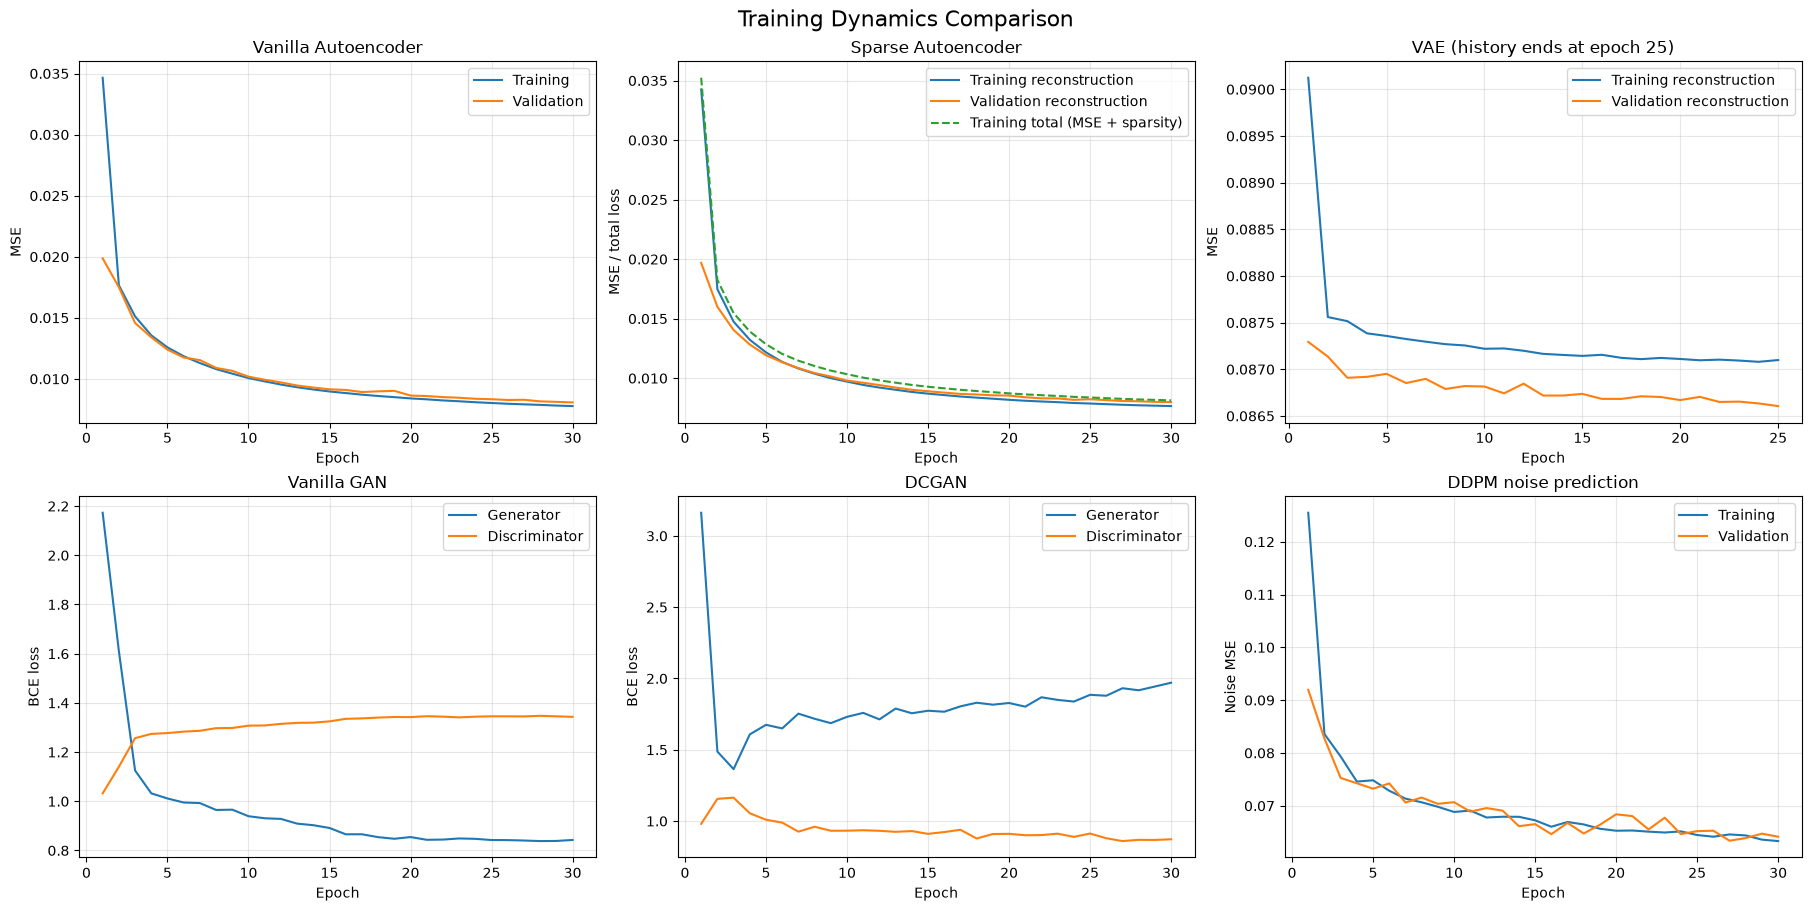

Saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\training_dynamics_comparison.png


In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9), constrained_layout=True)

ax = axes[0, 0]
history = metrics["vanilla_ae"]["history"]
epochs = [item["epoch"] for item in history]
ax.plot(epochs, [item["train_loss"] for item in history], label="Training")
ax.plot(epochs, [item["val_loss"] for item in history], label="Validation")
ax.set_title("Vanilla Autoencoder")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE")
ax.legend()

ax = axes[0, 1]
history = checkpoints["sparse_ae"]["history"]
epochs = range(1, len(history["train_reconstruction_loss"]) + 1)
ax.plot(epochs, history["train_reconstruction_loss"], label="Training reconstruction")
ax.plot(epochs, history["val_reconstruction_loss"], label="Validation reconstruction")
ax.plot(
    epochs,
    history["train_total_loss"],
    label="Training total (MSE + sparsity)",
    linestyle="--",
)
ax.set_title("Sparse Autoencoder")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE / total loss")
ax.legend()

ax = axes[0, 2]
history = checkpoints["vae"]["history"]
epochs = range(1, len(history["train_reconstruction_loss"]) + 1)
ax.plot(epochs, history["train_reconstruction_loss"], label="Training reconstruction")
ax.plot(epochs, history["val_reconstruction_loss"], label="Validation reconstruction")
ax.set_title(f"VAE (history ends at epoch {len(epochs)})")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE")
ax.legend()

ax = axes[1, 0]
history = checkpoints["vanilla_gan"]["history"]
epochs = range(1, len(history["generator_loss"]) + 1)
ax.plot(epochs, history["generator_loss"], label="Generator")
ax.plot(epochs, history["discriminator_loss"], label="Discriminator")
ax.set_title("Vanilla GAN")
ax.set_xlabel("Epoch")
ax.set_ylabel("BCE loss")
ax.legend()

ax = axes[1, 1]
history = checkpoints["dcgan"]["history"]
epochs = range(1, len(history["generator_loss"]) + 1)
ax.plot(epochs, history["generator_loss"], label="Generator")
ax.plot(epochs, history["discriminator_loss"], label="Discriminator")
ax.set_title("DCGAN")
ax.set_xlabel("Epoch")
ax.set_ylabel("BCE loss")
ax.legend()

ax = axes[1, 2]
if ddpm_history is not None:
    ax.plot(ddpm_history["epoch"], ddpm_history["train_loss"], label="Training")
    ax.plot(ddpm_history["epoch"], ddpm_history["val_loss"], label="Validation")
    ax.set_title("DDPM noise prediction")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Noise MSE")
    ax.legend()
else:
    fallback = FIGURES_DIR / "ddpm_training_curves.png"
    if fallback.is_file():
        ax.imshow(plt.imread(fallback))
        ax.axis("off")
        ax.set_title("DDPM (existing curve; history unavailable)")
    else:
        ax.text(
            0.5,
            0.5,
            "DDPM history unavailable",
            ha="center",
            va="center",
            transform=ax.transAxes,
        )
        ax.axis("off")

fig.suptitle("Training Dynamics Comparison", fontsize=16)

dynamics_path = FIGURES_DIR / "training_dynamics_comparison.png"
fig.savefig(dynamics_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Saved: {dynamics_path}")

<!-- @format -->

## DDPM reverse diffusion trajectory

The trajectory starts from Gaussian noise (t = 500) and then follows the
selected denoising steps in chronological order down to t = 0.


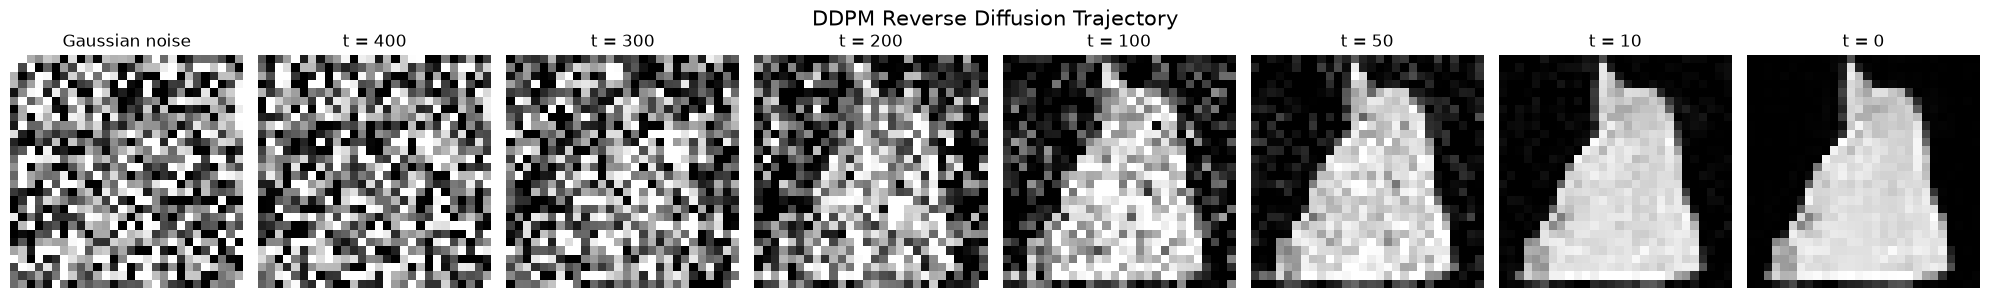

Saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\ddpm_reverse_diffusion_trajectory.png


In [17]:
fig, axes = plt.subplots(1, len(ddpm_trajectory), figsize=(20, 3))

for ax, (timestep, image) in zip(axes, ddpm_trajectory):
    display_image = (image[0, 0] + 1.0) / 2.0
    ax.imshow(display_image, cmap="gray", vmin=0, vmax=1)
    label = "Gaussian noise" if timestep == TIMESTEPS else f"t = {timestep}"
    ax.set_title(label)
    ax.axis("off")

fig.suptitle("DDPM Reverse Diffusion Trajectory", fontsize=15)
plt.tight_layout()

trajectory_path = FIGURES_DIR / "ddpm_reverse_diffusion_trajectory.png"
fig.savefig(trajectory_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Saved: {trajectory_path}")

<!-- @format -->

## Combined dynamics and trajectory figure


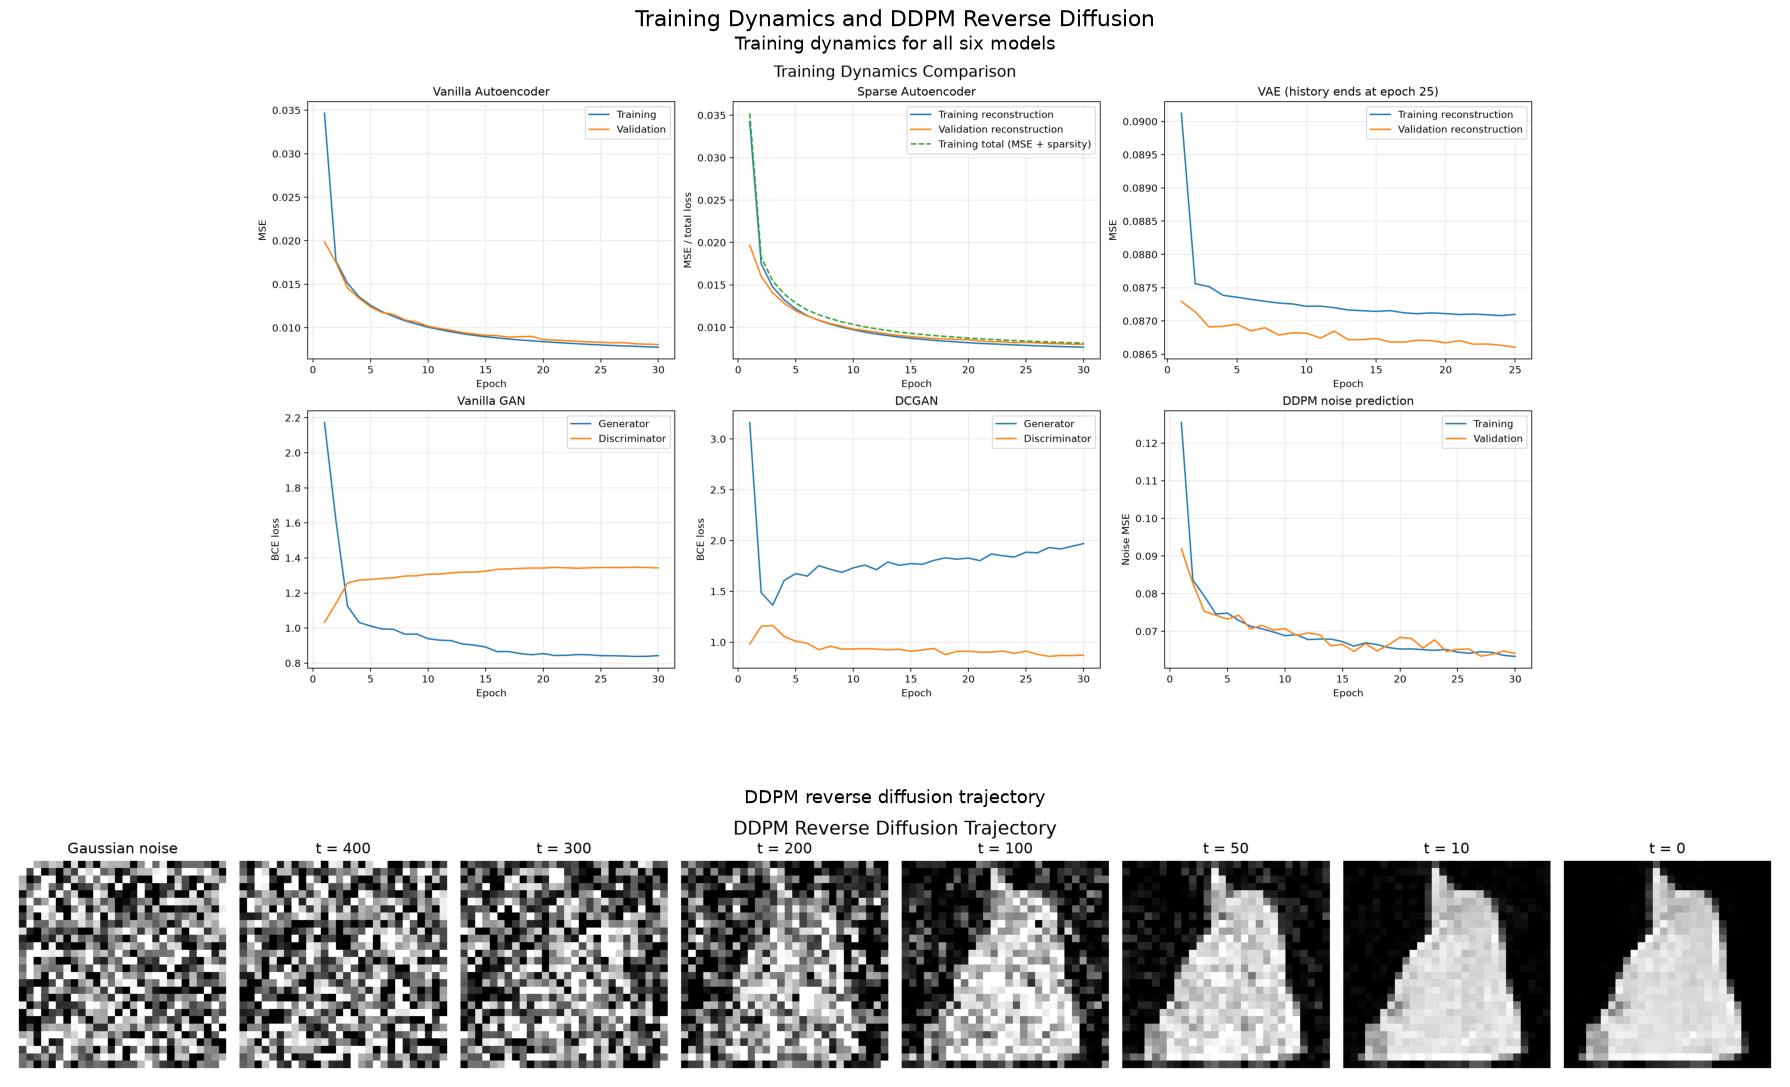

Saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\training_dynamics_and_ddpm_trajectory.png


In [18]:
fig, axes = plt.subplots(2, 1, figsize=(18, 13))

axes[0].imshow(plt.imread(dynamics_path))
axes[0].set_title("Training dynamics for all six models", fontsize=13)
axes[0].axis("off")

axes[1].imshow(plt.imread(trajectory_path))
axes[1].set_title("DDPM reverse diffusion trajectory", fontsize=13)
axes[1].axis("off")

fig.suptitle("Training Dynamics and DDPM Reverse Diffusion", fontsize=16)
plt.tight_layout()

combined_figure_path = FIGURES_DIR / "training_dynamics_and_ddpm_trajectory.png"
fig.savefig(combined_figure_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Saved: {combined_figure_path}")

<!-- @format -->

## Research questions: evidence from this run


In [ ]:
mlp_metrics = metrics["mlp_classifier"]
mlp_analysis = metrics["mlp_classifier_analysis"]
mlp_test = mlp_analysis["experiment_3"]["test_metrics"]

best_reconstruction = min(
    recomputed_metrics,
    key=lambda name: recomputed_metrics[name]["mse"],
)

vanilla_gan_history = checkpoints["vanilla_gan"]["history"]
dcgan_history = checkpoints["dcgan"]["history"]

print("Observed in this run:\n")

print("Reconstruction fidelity:")
print(
    f"{best_reconstruction} has the lowest recomputed test MSE "
    f"({recomputed_metrics[best_reconstruction]['mse']:.6f})."
)
print(
    f"Vanilla AE: MSE {recomputed_metrics['Vanilla AE']['mse']:.6f}, "
    f"PSNR {recomputed_metrics['Vanilla AE']['psnr']:.2f} dB, "
    f"SSIM {recomputed_metrics['Vanilla AE']['ssim']:.4f}."
)
print(
    f"Sparse AE: MSE {recomputed_metrics['Sparse AE']['mse']:.6f}, "
    f"PSNR {recomputed_metrics['Sparse AE']['psnr']:.2f} dB, "
    f"SSIM {recomputed_metrics['Sparse AE']['ssim']:.4f}."
)
print(
    f"VAE: MSE {recomputed_metrics['VAE']['mse']:.6f}, "
    f"PSNR {recomputed_metrics['VAE']['psnr']:.2f} dB, "
    f"SSIM {recomputed_metrics['VAE']['ssim']:.4f}."
)

print("\nGAN loss balance:")
print(
    f"Vanilla GAN generator loss: "
    f"{vanilla_gan_history['generator_loss'][0]:.3f} -> "
    f"{vanilla_gan_history['generator_loss'][-1]:.3f}."
)
print(
    f"Vanilla GAN discriminator loss: "
    f"{vanilla_gan_history['discriminator_loss'][0]:.3f} -> "
    f"{vanilla_gan_history['discriminator_loss'][-1]:.3f}."
)
print(
    f"DCGAN generator loss: "
    f"{dcgan_history['generator_loss'][0]:.3f} -> "
    f"{dcgan_history['generator_loss'][-1]:.3f}."
)
print(
    f"DCGAN discriminator loss: "
    f"{dcgan_history['discriminator_loss'][0]:.3f} -> "
    f"{dcgan_history['discriminator_loss'][-1]:.3f}."
)

print("\nDDPM training:")
if ddpm_history is not None:
    print(f"Final training noise MSE: {ddpm_history['train_loss'][-1]:.6f}.")
    print(f"Final validation noise MSE: {ddpm_history['val_loss'][-1]:.6f}.")
else:
    print("Per-epoch training history was unavailable.")

print("\nMLP classifier limitations:")
print(f"Classifier test accuracy: {mlp_metrics['test_accuracy']:.4f}.")
print(
    f"Frozen decoder reconstruction: "
    f"MSE {mlp_test['test_mse']:.6f}, "
    f"PSNR {mlp_test['test_psnr']:.2f} dB, "
    f"SSIM {mlp_test['test_ssim']:.4f}."
)
print(
    "Classifier features do not necessarily preserve all pixel-level "
    "reconstruction information."
)

print("\nGenerated samples (visual observation):")
print(
    "DCGAN and DDPM produce the most recognisable garment silhouettes. "
    "Vanilla GAN samples are substantially noisier, and VAE samples are "
    "near-uniform blobs. This is a visual observation, not a quantitative score."
)

print("\nLatent interpolation (visual observation):")
print(
    "DCGAN changes smoothly from one garment to another. AE and Sparse AE "
    "interpolate between textured, noisy reconstructions. VAE remains blob-like, "
    "while Vanilla GAN retains a checkerboard-like texture."
)

print("\nFID:")
print(
    "No FID score is available for any model. Sample fidelity and diversity "
    "cannot be ranked quantitatively using FID."
)


### Observed in this run

**Reconstruction fidelity.** Sparse AE has the lowest recomputed test MSE (0.007944). Vanilla AE: MSE 0.008022, PSNR 20.97 dB, SSIM 0.7476. Sparse AE: MSE 0.007944, PSNR 21.01 dB, SSIM 0.7519. VAE: MSE 0.087502, PSNR 10.58 dB, SSIM 0.1288.

**GAN loss balance.** Vanilla GAN generator loss moved from 2.173 to 0.843, while discriminator loss moved from 1.032 to 1.343. DCGAN generator loss moved from 3.162 to 1.970, while discriminator loss moved from 0.981 to 0.872.

**DDPM training.** Final recorded training noise MSE is 0.063319 and final validation noise MSE is 0.064141.

**MLP classifier limitations.** The classifier reached test accuracy 0.8934. Reconstructing through its frozen 64-D features with a separately trained decoder reached MSE 0.017882, PSNR 18.27 dB and SSIM 0.6543, which is worse than the AE-family reconstruction scores above.

**Generated samples (visual observation).** In the random-generation panel, DCGAN and DDPM produce the most recognisable garment silhouettes. Vanilla GAN samples are substantially noisier, and the VAE samples are near-uniform blobs. This is a visual observation from the saved figure, not a quantitative score.

**Latent interpolation (visual observation).** DCGAN changes smoothly from one garment to another. The AE and Sparse AE rows interpolate between textured, noisy reconstructions, the VAE row stays blob-like throughout, and the Vanilla GAN row keeps a checkerboard-like texture. This is again a visual observation.

**FID.** No FID score is available for any model, so sample fidelity and diversity cannot be ranked quantitatively. The generation grids are the only direct evidence for sample quality in this notebook.


<!-- @format -->

### Hypotheses (not directly measured here)

- The AE-family reconstructions look smoother because a per-pixel MSE objective
  rewards averaging over plausible high-frequency details. This is a hypothesis
  about the objective, not a measured sharpness result.
- The VAE's high reconstruction MSE, low SSIM and blob-like samples are consistent
  with posterior collapse: the recorded KL is almost zero, so the latent code
  carries little sample-specific information and the decoder falls back to an
  average-like output. This is a hypothesis; the measured evidence is the
  reconstruction metrics and near-zero KL.
- GAN loss values are not reliable indicators of visual quality. A stable-looking
  generator/discriminator balance can still produce mode collapse or artifacts,
  so the generation grids must be inspected directly.
- Smooth latent interpolation in the AE-family is expected because nearby codes
  decode to nearby pixel averages. GAN latent spaces are not trained for metric
  interpolation, so their transitions may be less semantically smooth even when
  the endpoint samples look plausible.
- The MLP's 64-D hidden layer is optimised for class separation, not for
  reconstruction or generation. The frozen-decoder result supports the view that
  a discriminative representation discards information needed for faithful
  synthesis.

### Recommendations for industrial applications

- Use AE or Sparse AE when compression, denoising or fast reconstruction matters
  more than sample realism; they are the cheapest and most accurate reconstructors
  in this comparison.
- Use VAE when a smooth, samplable latent space is required and some blur is
  acceptable.
- Use GANs when perceptual realism is the priority and training stability can be
  monitored carefully; keep discriminator/generator diagnostics and inspect
  samples, not only losses.
- Use DDPM when sample quality matters more than inference cost. Its reverse
  process is far slower than a single generator forward pass.
- Before deployment, add FID or precision/recall on a held-out set and evaluate
  the model on the target domain; none of the current numbers measure sample
  diversity or downstream utility.
